In [38]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()  # încarcă automat contul salvat


for b in service.backends():
    print(b.name, b.num_qubits, "qubiți")

backend = service.least_busy(operational=True, simulator=False)
print("Cel mai liber acum:", backend.name)

ibm_boston 156 qubiți
ibm_fez 156 qubiți
ibm_kingston 156 qubiți
ibm_marrakesh 156 qubiți
ibm_phoenix 120 qubiți
ibm_pittsburgh 156 qubiți
Cel mai liber acum: ibm_fez


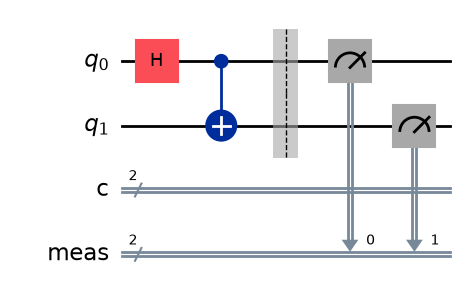

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.executor_sampler import Sampler
from qiskit.visualization import plot_histogram

# Bell gate
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)

# care e diferenta intre measure(0,1) si measure_all() ?
# qc.measure(0,1) -> masoara q0 si scrie rez in bitul clasic 1
qc.measure_all()
qc.draw("mpl")

{'00': 479, '11': 521}


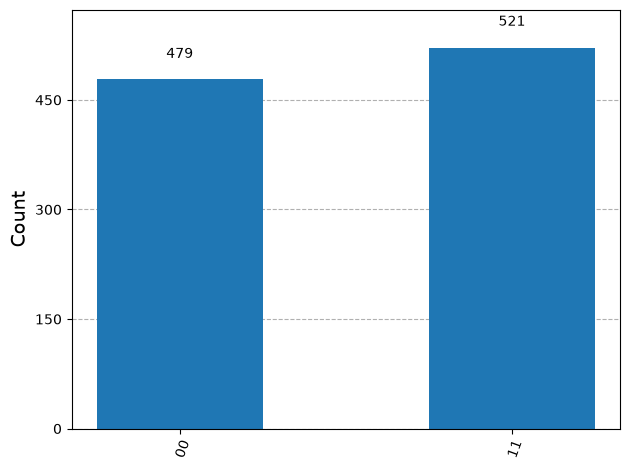

In [40]:
# run implementation on Aer Simulator

# transpiler
sim = AerSimulator()
pm = generate_preset_pass_manager(backend=sim, optimization_level=1)
isa_qc = pm.run(qc)

# sampler
sampler = Sampler(mode=sim)
job = sampler.run([isa_qc], shots=1000)
result = job.result()

# results
counts = result[0].data.meas.get_counts()
print(counts)
plot_histogram(counts)

In [ ]:
# run implementation on QPU
# a rulat 2 secunde - am vazut din ibm q platform

from qiskit_ibm_runtime import QiskitRuntimeService

# comenteaza - for safety
# service = QiskitRuntimeService(name="default-ibm-quantum-platform")
# backend = service.least_busy(operational=True, simulator=False)

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc)

sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=1000)
print(job.job_id())   # notează-l în jurnal

result = job.result() # aici aștepți coada
counts = result[0].data.meas.get_counts()
plot_histogram(counts)

NameError: name 'backend' is not defined

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(name="default-ibm-quantum-platform")
job = service.job("dbd7dt7i0auc7394s3lg")

print("Backend:", job.backend().name)
print("Data:", job.creation_date)
print("Timp QPU:", job.usage(), "secunde")

Backend: ibm_fez
Data: 2026-10-22 23:49:56.477559+03:00
Timp QPU: 2 secunde
